# 0. Loading the libraries and the dataset

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from collections import Counter

In [2]:
df = pd.read_excel(r"C:\Users\Dell\Documents\Elevator BTP\elevator_fault_dataset_full.xlsx")
df.head()

,Timestamp,Motor_Current,Motor_Voltage,Vibration_Level,Speed,Cabin_Position,Cabin_Acceleration,Cabin_Deceleration,Door_Operation_Time,Braking_Force,...,Control_System_Delay,Frequency_of_Emergency_Stops,Button_Press_Logs,Door_Obstruction_Events,Overload_Events,Health_Indices,RUL,Fault_State,Fault_Category,Fault_Severity
0,2020-01-01 00:00:00,22.289903,241.253222,1.393233,3.519079,19,0.349191,0.358643,5.747832,112.280046,...,0.097096,3,61.037683,0,0,171.975594,893.941155,1,Door Failure,Minor
1,2020-01-01 01:00:00,25.240487,236.078046,0.090303,2.226921,9,0.260127,0.266565,7.552277,142.770141,...,0.075588,1,15.653676,0,0,150.250886,2130.455491,0,Brake Failure,Critical
2,2020-01-01 02:00:00,32.769471,432.220975,0.932987,2.523211,20,0.291057,0.161099,7.703547,98.016876,...,0.091237,3,25.963784,0,0,164.327588,2472.445475,0,Motor Malfunction,Minor
3,2020-01-01 03:00:00,34.913962,645.108627,0.490413,4.910428,20,0.439094,0.214058,8.335525,75.588623,...,0.128085,2,25.590539,0,0,142.256458,1753.632090,0,Motor Malfunction,Moderate
4,2020-01-01 04:00:00,27.799073,224.451891,0.844176,5.188226,20,0.566116,0.365294,4.717031,95.882924,...,0.112181,2,41.910883,0,0,89.765157,2399.361778,0,Sensor Error,Critical


In [23]:
df.columns 

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity'],
      dtype='object')

# 1. Univariate Analysis

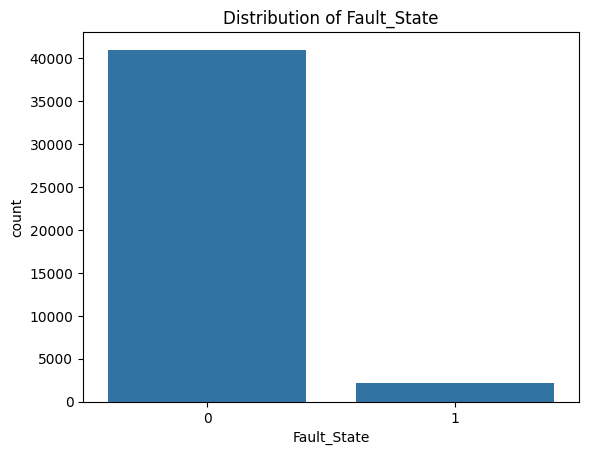

In [43]:
sns.countplot(x='Fault_State', data=df)
plt.title('Distribution of Fault_State')
plt.show()

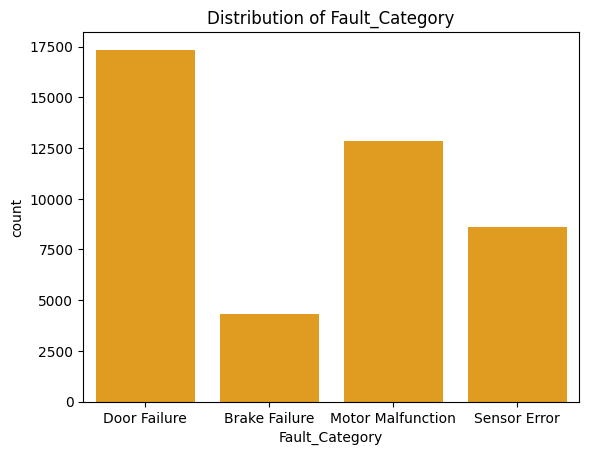

In [3]:
sns.countplot(x='Fault_Category', data=df, color='orange')
plt.title('Distribution of Fault_Category')
plt.show()

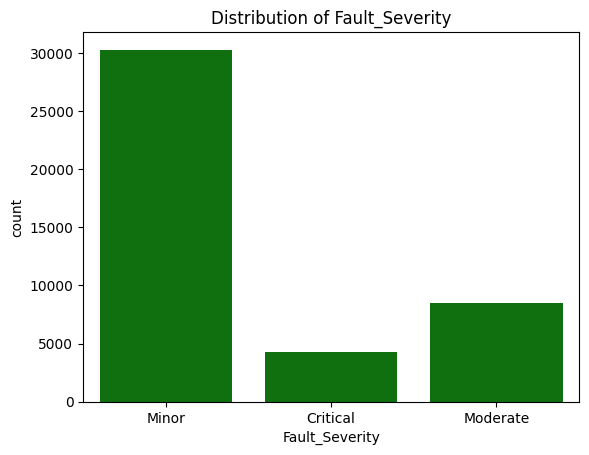

In [4]:
sns.countplot(x='Fault_Severity', data=df, color='green')
plt.title('Distribution of Fault_Severity')
plt.show()

# 2. Bivariate/Multivariate Analysis

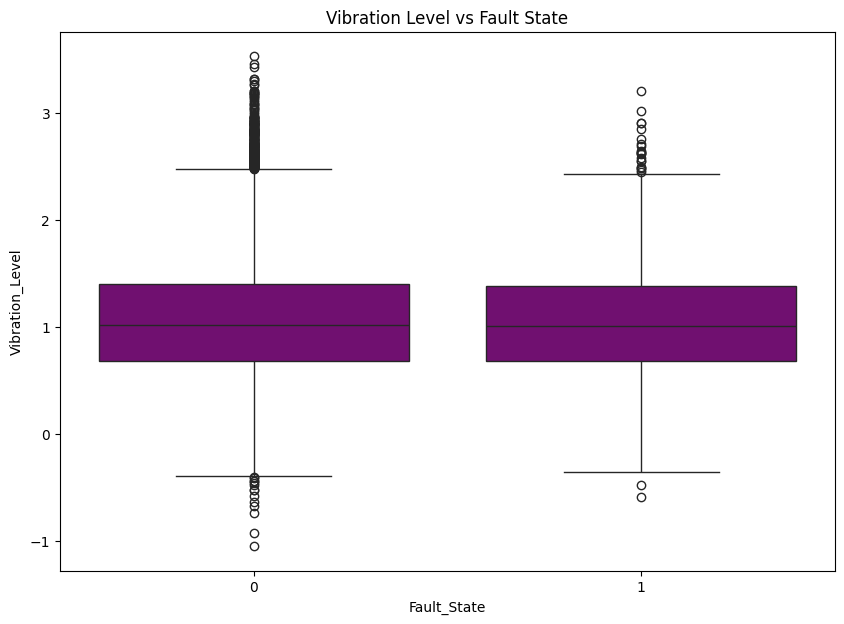

In [ ]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='Fault_State', y='Vibration_Level', data=df, color='purple')
plt.title('Vibration Level vs Fault State')
plt.show()

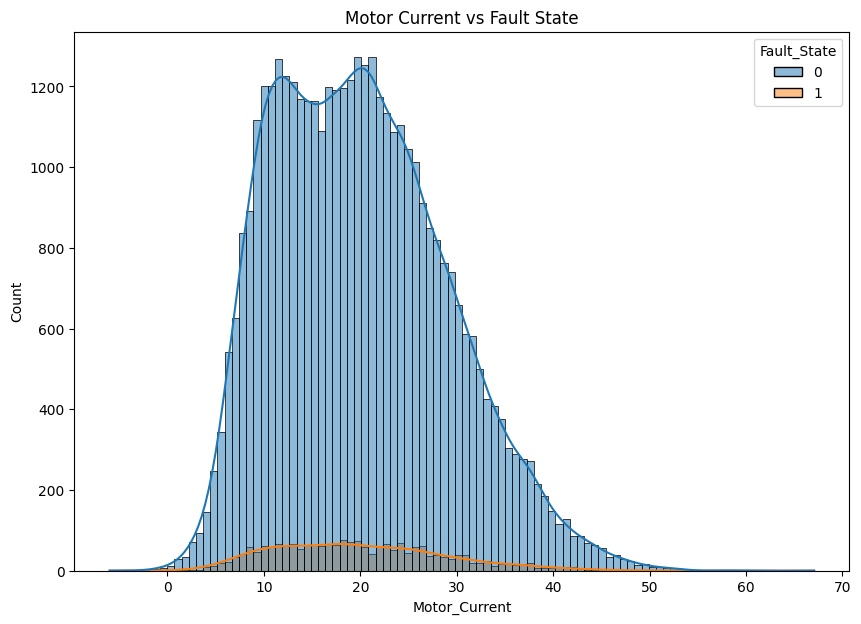

In [55]:
plt.figure(figsize=(10, 7))
sns.histplot(data=df, x='Motor_Current', hue='Fault_State', kde=True)
plt.title('Motor Current vs Fault State')
plt.show()

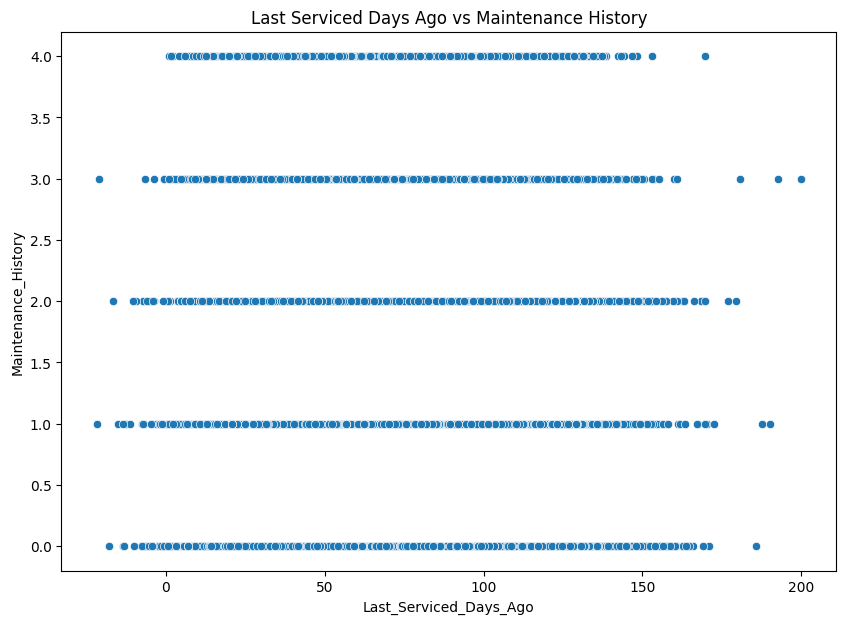

In [56]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x='Last_Serviced_Days_Ago', y='Maintenance_History', data=df)
plt.title('Last Serviced Days Ago vs Maintenance History')
plt.show()

In [58]:
df.columns

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity'],
      dtype='object')

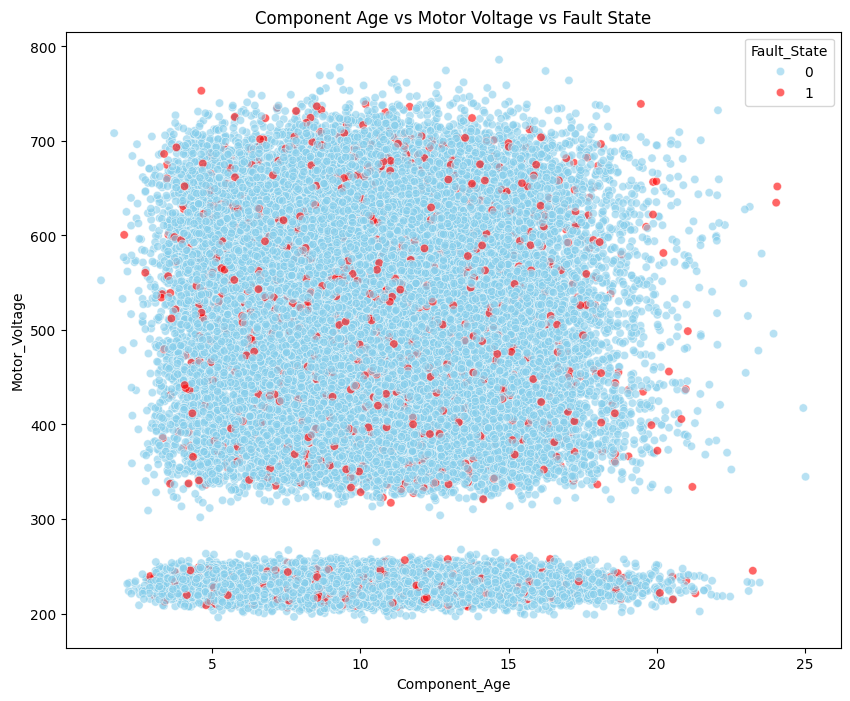

In [62]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Component_Age', 
    y='Motor_Voltage', 
    hue='Fault_State',        
    data=df, 
    alpha=0.6,                
    palette=['skyblue', 'red'] 
)
plt.title('Component Age vs Motor Voltage vs Fault State')
plt.xlabel('Component_Age')
plt.ylabel('Motor_Voltage')
plt.legend(title='Fault_State')
plt.show()

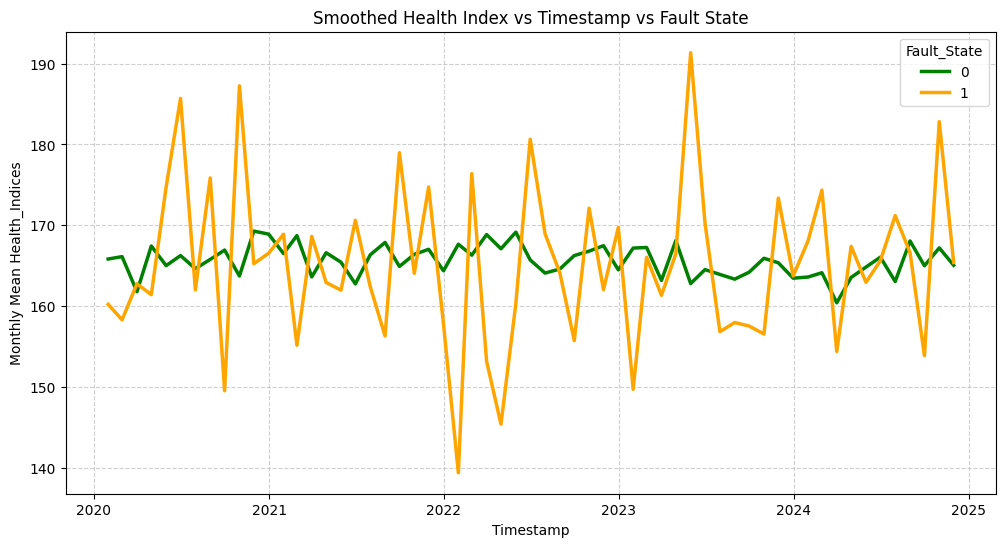

In [66]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df_indexed = df.set_index('Timestamp')

# Resample Data Monthly and Calculate Mean Health Indices to smoothen out the plot trends
df_resampled = df_indexed.groupby('Fault_State')['Health_Indices'].resample('ME').mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(
    x='Timestamp',
    y='Health_Indices',
    hue='Fault_State',
    data=df_resampled,
    palette=['green', 'orange'],
    linewidth=2.5
)

plt.title('Smoothed Health Index vs Timestamp vs Fault State')
plt.xlabel('Timestamp')
plt.ylabel('Monthly Mean Health_Indices')
plt.legend(title='Fault_State')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

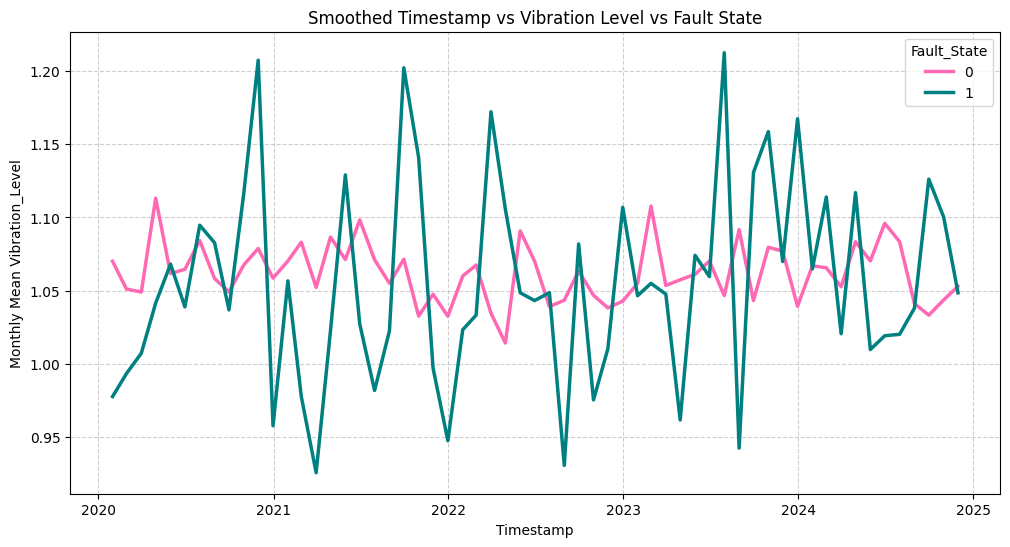

In [81]:
df_resampled = df_indexed.groupby('Fault_State')['Vibration_Level'].resample('ME').mean().reset_index()

# Plot the Smoothed Trend
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='Timestamp',
    y='Vibration_Level',
    hue='Fault_State',
    data=df_resampled, 
    palette=['hotpink', 'teal'], 
    linewidth=2.5
)

plt.title('Smoothed Timestamp vs Vibration Level vs Fault State')
plt.xlabel('Timestamp')
plt.ylabel('Monthly Mean Vibration_Level')
plt.legend(title='Fault_State')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

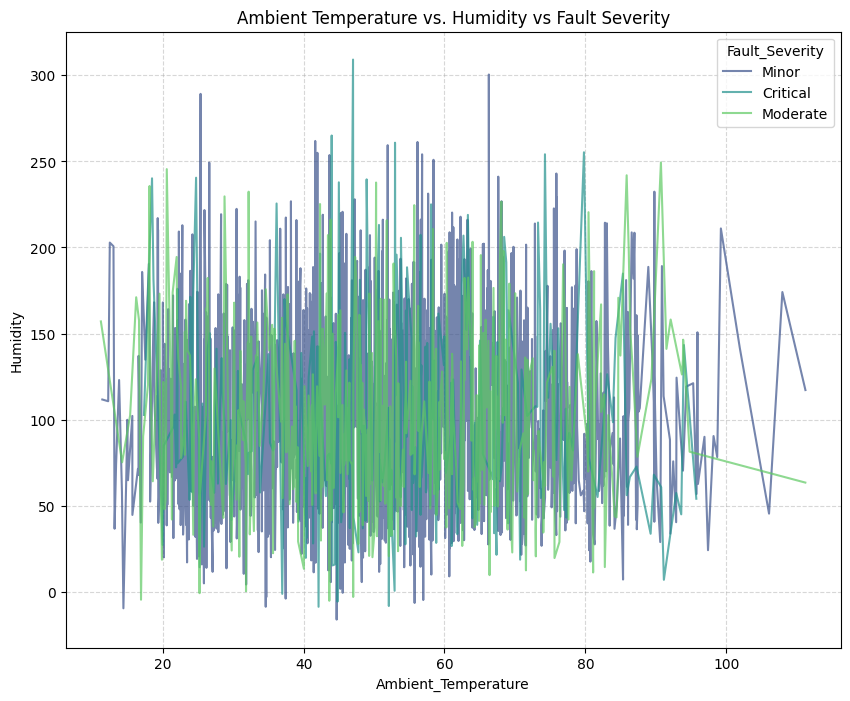

In [70]:
plt.figure(figsize=(10, 8))
sns.lineplot(
    data=df.sample(frac=0.05),  
    x='Ambient_Temperature',
    y='Humidity',
    hue='Fault_Severity',
    alpha=0.7,
    palette='viridis'
)
plt.title('Ambient Temperature vs. Humidity vs Fault Severity')
plt.xlabel('Ambient_Temperature')
plt.ylabel('Humidity')
plt.legend(title='Fault_Severity')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

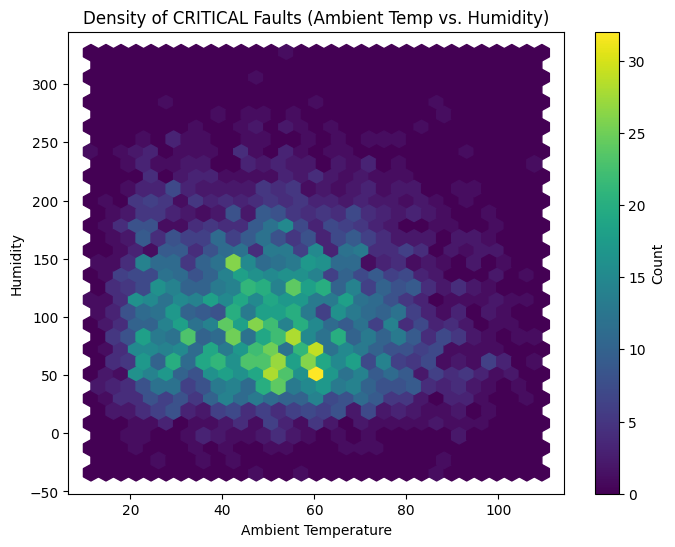

In [74]:
critical_df = df[df['Fault_Severity'] == 'Critical']

plt.figure(figsize=(8, 6))
plt.hexbin(
    critical_df['Ambient_Temperature'],
    critical_df['Humidity'],
    gridsize=30, # Number of hexagons
    cmap='viridis'
)
plt.title('Density of CRITICAL Faults (Ambient Temp vs. Humidity)')
plt.xlabel('Ambient Temperature')
plt.ylabel('Humidity')
plt.colorbar(label='Count')
plt.show()

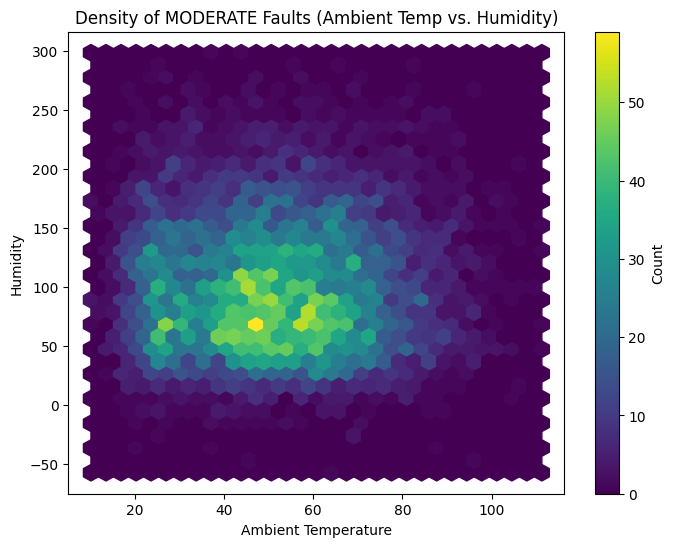

In [75]:
moderate_df = df[df['Fault_Severity'] == 'Moderate']

plt.figure(figsize=(8, 6))
plt.hexbin(
    moderate_df['Ambient_Temperature'],
    moderate_df['Humidity'],
    gridsize=30, 
    cmap='viridis'
)
plt.title('Density of MODERATE Faults (Ambient Temp vs. Humidity)')
plt.xlabel('Ambient Temperature')
plt.ylabel('Humidity')
plt.colorbar(label='Count')
plt.show()

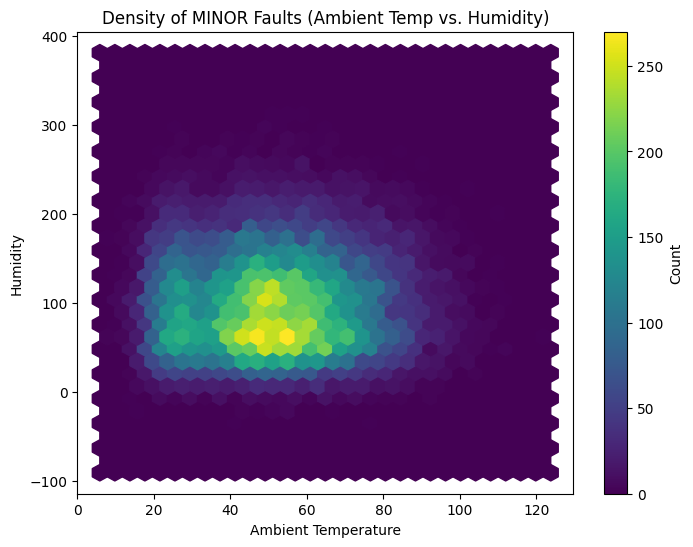

In [76]:
minor_df = df[df['Fault_Severity'] == 'Minor']

plt.figure(figsize=(8, 6))
plt.hexbin(
    minor_df['Ambient_Temperature'],
    minor_df['Humidity'],
    gridsize=30, 
    cmap='viridis'
)
plt.title('Density of MINOR Faults (Ambient Temp vs. Humidity)')
plt.xlabel('Ambient Temperature')
plt.ylabel('Humidity')
plt.colorbar(label='Count')
plt.show()

In [82]:
df.columns

Index(['Timestamp', 'Motor_Current', 'Motor_Voltage', 'Vibration_Level',
       'Speed', 'Cabin_Position', 'Cabin_Acceleration', 'Cabin_Deceleration',
       'Door_Operation_Time', 'Braking_Force', 'Rope_Tension',
       'Guide_Rail_Condition_Index', 'Pulley_Wear', 'Lubrication_Levels',
       'Power_Consumption', 'Battery_Health', 'Voltage_Fluctuations',
       'Current_Harmonics', 'Ambient_Temperature', 'Humidity', 'Dust_Levels',
       'External_Vibration_Levels', 'Load', 'Passenger_Count',
       'Number_of_Trips', 'Stop_Frequency', 'Travel_Distance',
       'Call_Waiting_Time', 'Fault_Logs', 'Maintenance_History',
       'Component_Age', 'Last_Serviced_Days_Ago', 'MTTF', 'Signal_Noise',
       'Temperature_Gradient', 'Door_Sensor_Readings', 'Control_System_Delay',
       'Frequency_of_Emergency_Stops', 'Button_Press_Logs',
       'Door_Obstruction_Events', 'Overload_Events', 'Health_Indices', 'RUL',
       'Fault_State', 'Fault_Category', 'Fault_Severity'],
      dtype='object')

# 3. Correlations 

In [24]:
numeric_cols = df.select_dtypes(include='number')

# Compute correlation matrix
corr = numeric_cols.corr()

# Extract correlations with 'Fault_State', drop self-correlation safely
corr_with_fault = corr.loc[corr.index != 'Fault_State', ['Fault_State']]

corr_with_fault.sort_values(by='Fault_State', ascending=False)

,Fault_State
Component_Age,0.007668
Motor_Voltage,0.007242
RUL,0.006925
Power_Consumption,0.006879
Voltage_Fluctuations,0.005999
Fault_Logs,0.005880
Humidity,0.005056
Last_Serviced_Days_Ago,0.004417
Signal_Noise,0.004103
Button_Press_Logs,0.003507


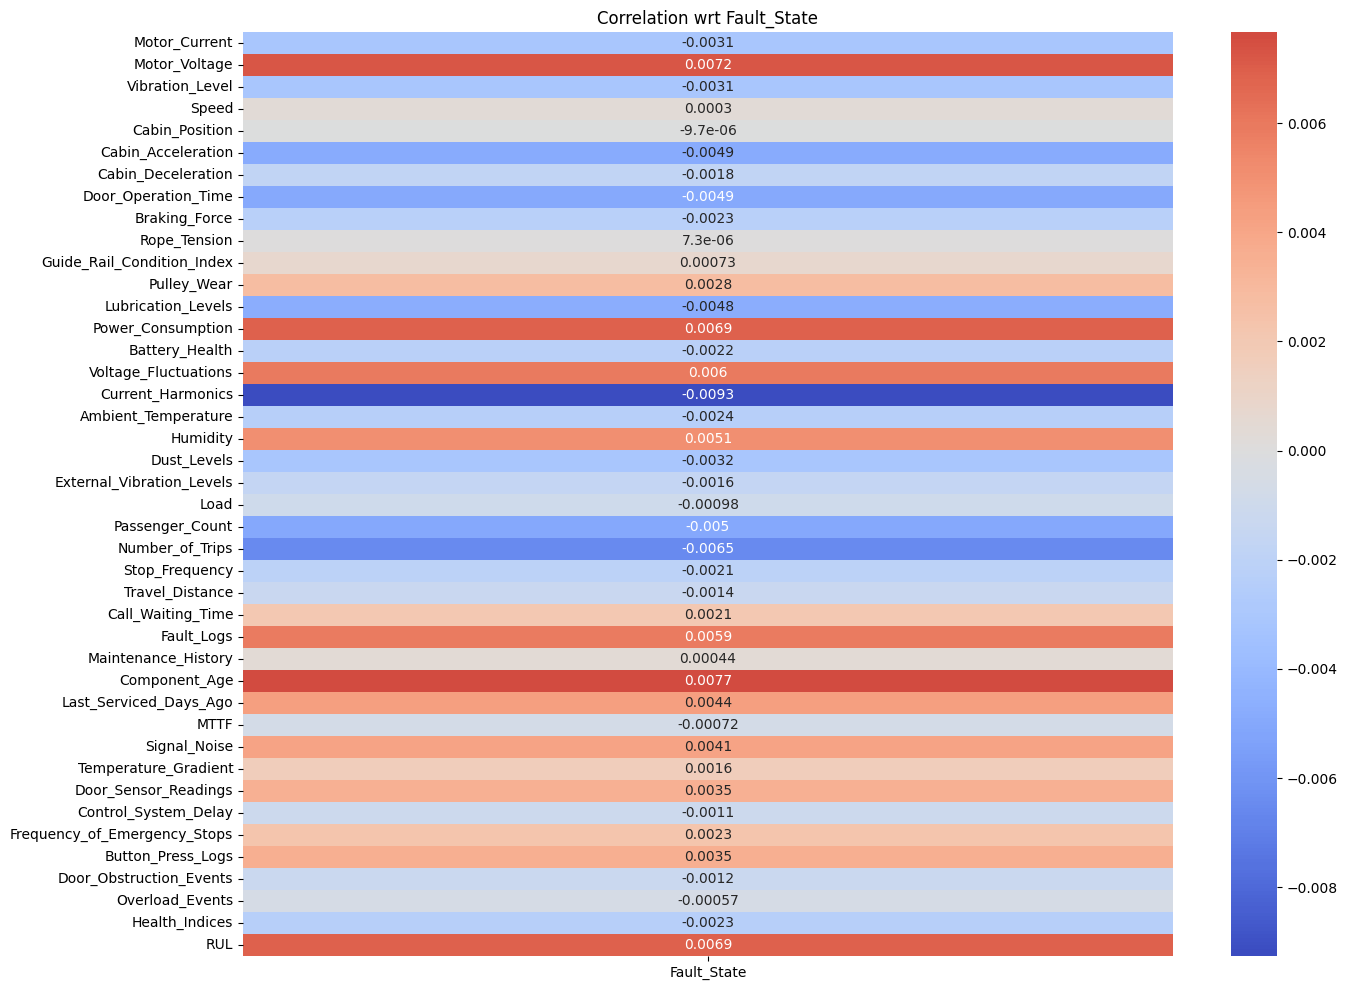

In [27]:
plt.figure(figsize=(15, 12)) 
sns.heatmap(corr_with_fault, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation wrt Fault_State')
plt.show()

In [28]:
corr_series = corr_with_fault['Fault_State']
corr_series

Motor_Current                  -0.003133
Motor_Voltage                   0.007242
Vibration_Level                -0.003126
Speed                           0.000298
Cabin_Position                 -0.000010
Cabin_Acceleration             -0.004870
Cabin_Deceleration             -0.001753
Door_Operation_Time            -0.004916
Braking_Force                  -0.002276
Rope_Tension                    0.000007
Guide_Rail_Condition_Index      0.000725
Pulley_Wear                     0.002767
Lubrication_Levels             -0.004756
Power_Consumption               0.006879
Battery_Health                 -0.002222
Voltage_Fluctuations            0.005999
Current_Harmonics              -0.009266
Ambient_Temperature            -0.002372
Humidity                        0.005056
Dust_Levels                    -0.003155
External_Vibration_Levels      -0.001648
Load                           -0.000976
Passenger_Count                -0.005026
Number_of_Trips                -0.006494
Stop_Frequency  

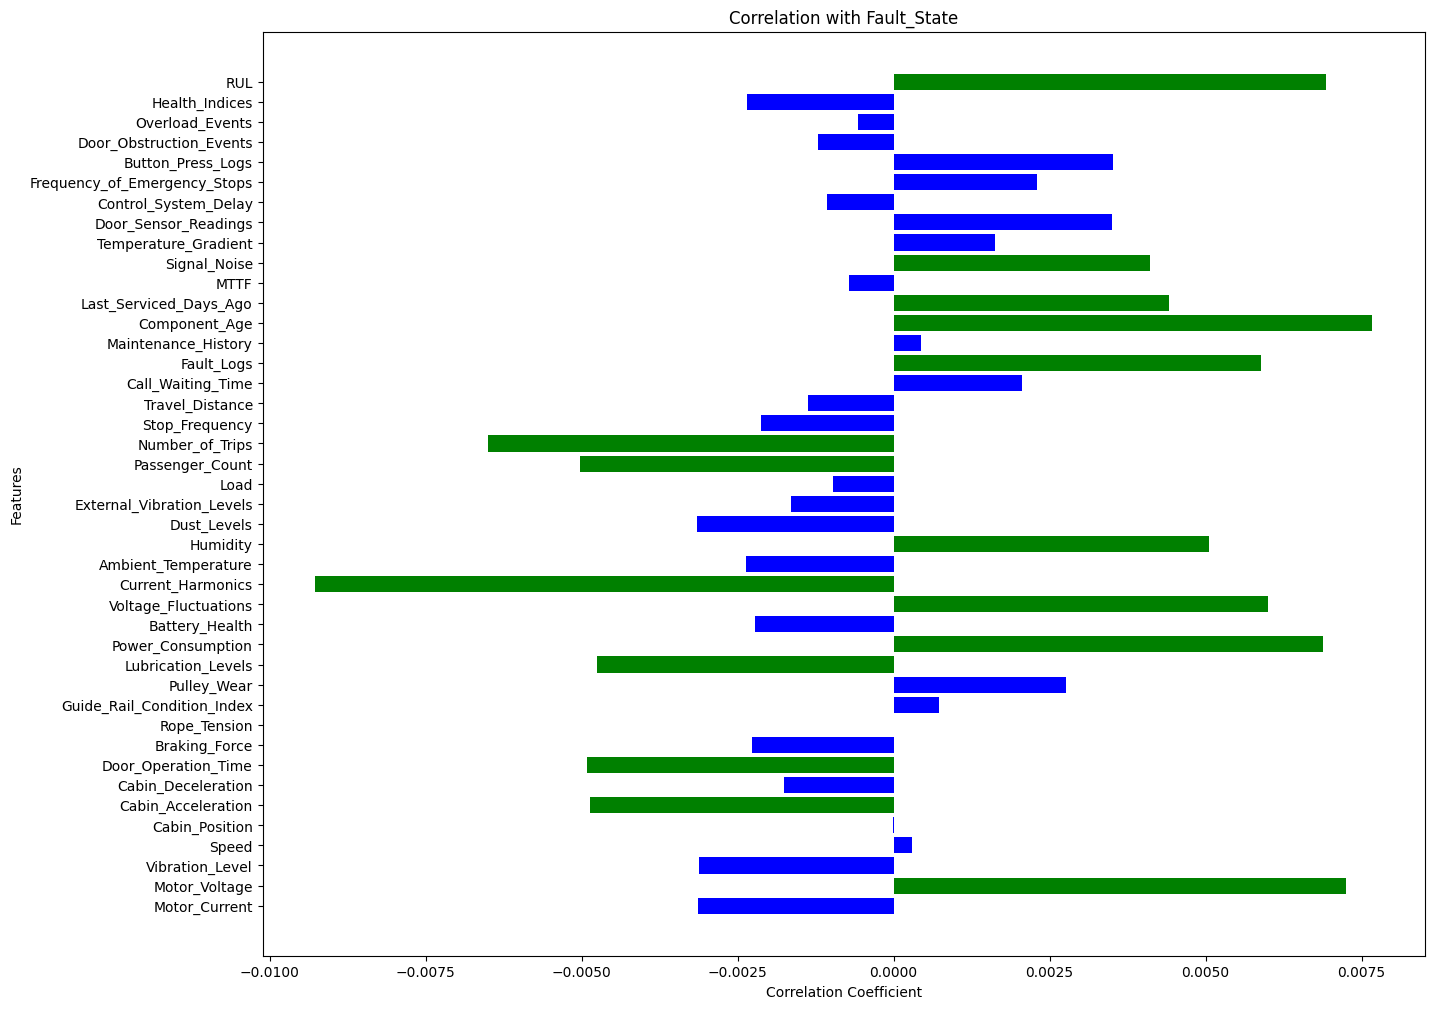

In [29]:
# 1. Generate the colors list (use this exact code)
colors = [
    'green' if c > 0.004 else 'green' if c < -0.004 else 'blue'
    for c in corr_series.values
]

# 2. Use the direct Matplotlib plotting function
plt.figure(figsize=(15, 12))
plt.barh(
    corr_series.index,    # Feature names (list of strings/index)
    corr_series.values,   # Correlation values (NumPy array of numbers)
    color=colors              # Color list (list of strings)
)

# 3. Set the labels and show
plt.title('Correlation with Fault_State')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.show()

In [ ]:
threshold = 0.004
filtered_corr = corr_with_fault[(corr_with_fault['Fault_State'] > threshold) | 
                                (corr_with_fault['Fault_State'] < -threshold)]
filtered_corr.sort_values(by='Fault_State', ascending=False)

,Fault_State
Component_Age,0.007668
Motor_Voltage,0.007242
RUL,0.006925
Power_Consumption,0.006879
Voltage_Fluctuations,0.005999
Fault_Logs,0.005880
Humidity,0.005056
Last_Serviced_Days_Ago,0.004417
Signal_Noise,0.004103
Lubrication_Levels,-0.004756


In [ ]:
columns_of_interest = [
    'Component_Age', 'Motor_Voltage', 'Power_Consumption', 'Voltage_Fluctuations', 
    'Fault_Logs', 'Humidity', 'Last_Serviced_Days_Ago', 'Signal_Noise', 'Lubrication_Levels', 
    'Cabin_Acceleration', 'Door_Operation_Time', 'Passenger_Count', 'Number_of_Trips', 
    'Current_Harmonics', 'Fault_State'
]

df_fault_analysis = df[columns_of_interest].copy()
df_fault_analysis.columns

Index(['Component_Age', 'Motor_Voltage', 'Power_Consumption',
       'Voltage_Fluctuations', 'Fault_Logs', 'Humidity',
       'Last_Serviced_Days_Ago', 'Signal_Noise', 'Lubrication_Levels',
       'Cabin_Acceleration', 'Door_Operation_Time', 'Passenger_Count',
       'Number_of_Trips', 'Current_Harmonics', 'Fault_State'],
      dtype='object')

# 4. Model Training 

In [ ]:
# Prepare features and target variable
features = [
    'Component_Age', 'Motor_Voltage', 'Power_Consumption', 
    'Voltage_Fluctuations', 'Fault_Logs', 'Humidity', 'Last_Serviced_Days_Ago', 
    'Signal_Noise', 'Lubrication_Levels', 'Cabin_Acceleration', 
    'Door_Operation_Time', 'Passenger_Count', 'Number_of_Trips', 
    'Current_Harmonics'
]
target = 'Fault_State'

X = df_fault_analysis[features]
y = df_fault_analysis[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [ ]:
# Making a pipeline for the baseline model
baseline_model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        random_state=42, 
        max_iter=1000,
        class_weight='balanced',
        solver='liblinear'
    ))
])

print("Training Baseline Logistic Regression Model")
baseline_model.fit(X_train, y_train)
print("Training complete")

# Model Evaluation
y_pred = baseline_model.predict(X_test)

print("\nModel Evaluation (Baseline Logistic Regression)")

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training Baseline Logistic Regression Model
Training complete

Model Evaluation (Baseline Logistic Regression)
Accuracy Score: 0.5137


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.51      0.67     12292
           1       0.05      0.52      0.09       633

    accuracy                           0.51     12925
   macro avg       0.50      0.51      0.38     12925
weighted avg       0.91      0.51      0.64     12925



In [ ]:
# Printing the pipeline
baseline_model

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
